In [ ]:
"""
BCSE331P - Assessment 8: K-Means and Hierarchical Clustering (Python)
NAME: P BALAJI SUBRAMANIAN
REG NO: 23BDS0271
"""

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

CSV_PATH = "orange_juice_withmissing.csv"

In [2]:
#K-MEANS CLUSTERING  
# 1-2. Load and view
df = pd.read_csv(CSV_PATH)
print("2. Dataset preview:\n", df.head(), "\n")

2. Dataset preview:
   Purchase  WeekofPurchase  StoreID  PriceCH  PriceMM  DiscCH  DiscMM  \
0       CH             237      1.0     1.75     1.99    0.00     0.0   
1       CH             239      1.0     1.75     1.99    0.00     0.3   
2       CH             245      1.0     1.86     2.09    0.17     0.0   
3       MM             227      1.0     1.69     1.69    0.00     0.0   
4       CH             228      7.0     1.69     1.69    0.00     0.0   

   SpecialCH  SpecialMM   LoyalCH  SalePriceMM  SalePriceCH  PriceDiff Store7  \
0        0.0        0.0  0.500000         1.99         1.75       0.24     No   
1        0.0        1.0  0.600000         1.69         1.75      -0.06     No   
2        0.0        0.0  0.680000         2.09         1.69       0.40     No   
3        0.0        0.0  0.400000         1.69         1.69       0.00     No   
4        0.0        0.0  0.956535         1.69         1.69       0.00    Yes   

   PctDiscMM  PctDiscCH  ListPriceDiff  STORE  
0   0

In [3]:
# 3. Missing values
print("3. Missing values:\n", df.isna().sum(), "\n")

3. Missing values:
 Purchase          0
WeekofPurchase    0
StoreID           1
PriceCH           1
PriceMM           4
DiscCH            2
DiscMM            4
SpecialCH         2
SpecialMM         5
LoyalCH           5
SalePriceMM       5
SalePriceCH       1
PriceDiff         1
Store7            0
PctDiscMM         5
PctDiscCH         2
ListPriceDiff     0
STORE             2
dtype: int64 



In [4]:
# 4. Dependent variable distribution
print("4. Purchase distribution:\n", df["Purchase"].value_counts(), "\n")

4. Purchase distribution:
 Purchase
CH    653
MM    417
Name: count, dtype: int64 



In [5]:
# 5. Numerical features only (drop Purchase, Store7). Median-impute the missing values.
num = df.select_dtypes(include=np.number).copy()
num = num.fillna(num.median())
print("5. Numerical features used:", list(num.columns), "\n")

5. Numerical features used: ['WeekofPurchase', 'StoreID', 'PriceCH', 'PriceMM', 'DiscCH', 'DiscMM', 'SpecialCH', 'SpecialMM', 'LoyalCH', 'SalePriceMM', 'SalePriceCH', 'PriceDiff', 'PctDiscMM', 'PctDiscCH', 'ListPriceDiff', 'STORE'] 



In [6]:
# 6. Standardise (like R scale())
X = StandardScaler().fit_transform(num)

In [7]:
# 7. K-means with 2 centres
km2 = KMeans(n_clusters=2, n_init=25, random_state=42).fit(X)

In [8]:
# 8. Results
print("8. Cluster sizes:", np.bincount(km2.labels_))
print("   Within-cluster SS:", round(km2.inertia_, 2))
print("   Cross-tab with Purchase:\n", pd.crosstab(km2.labels_, df["Purchase"]), "\n")

8. Cluster sizes: [351 719]
   Within-cluster SS: 13531.34
   Cross-tab with Purchase:
 Purchase   CH   MM
row_0             
0         161  190
1         492  227 



In [9]:
# 9. Cluster centres
print("9. Cluster centres (standardised):\n",
      pd.DataFrame(km2.cluster_centers_, columns=num.columns).round(3), "\n")

9. Cluster centres (standardised):
    WeekofPurchase  StoreID  PriceCH  PriceMM  DiscCH  DiscMM  SpecialCH  \
0          -0.177   -0.091   -0.243   -0.741  -0.040   1.076      0.221   
1           0.086    0.044    0.119    0.362   0.019  -0.525     -0.108   

   SpecialMM  LoyalCH  SalePriceMM  SalePriceCH  PriceDiff  PctDiscMM  \
0      0.590   -0.132       -1.297       -0.141     -1.137      1.083   
1     -0.288    0.064        0.633        0.069      0.555     -0.529   

   PctDiscCH  ListPriceDiff  STORE  
0     -0.035         -0.692 -0.013  
1      0.017          0.338  0.007   



In [10]:
# 10. WCSS for K = 1..10
wcss = [KMeans(n_clusters=k, n_init=25, random_state=42).fit(X).inertia_ for k in range(1, 11)]
print("10. WCSS:", dict(zip(range(1, 11), np.round(wcss, 2))), "\n")

10. WCSS: {1: np.float64(17120.0), 2: np.float64(13531.34), 3: np.float64(10488.24), 4: np.float64(8601.53), 5: np.float64(7679.19), 6: np.float64(6923.42), 7: np.float64(6186.74), 8: np.float64(5615.47), 9: np.float64(5207.91), 10: np.float64(4824.85)} 



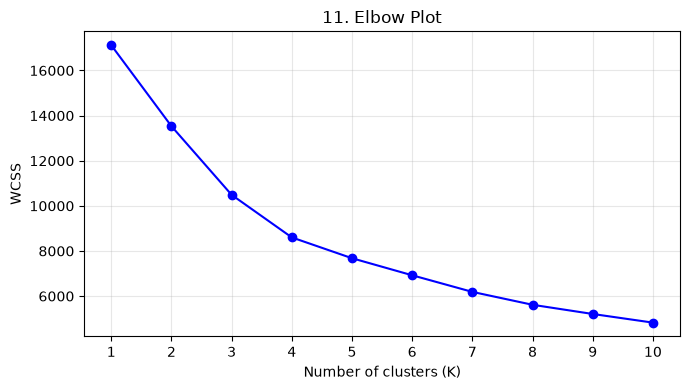

In [12]:
# 11. Elbow plot
plt.figure(figsize=(7, 4))
plt.plot(range(1, 11), wcss, "bo-")
plt.title("11. Elbow Plot"); plt.xlabel("Number of clusters (K)"); plt.ylabel("WCSS")
plt.xticks(range(1, 11)); plt.grid(alpha=0.3)
plt.tight_layout(); plt.show()

12. Elbow-recommended K = 3
    Cluster sizes: [324 642 104]


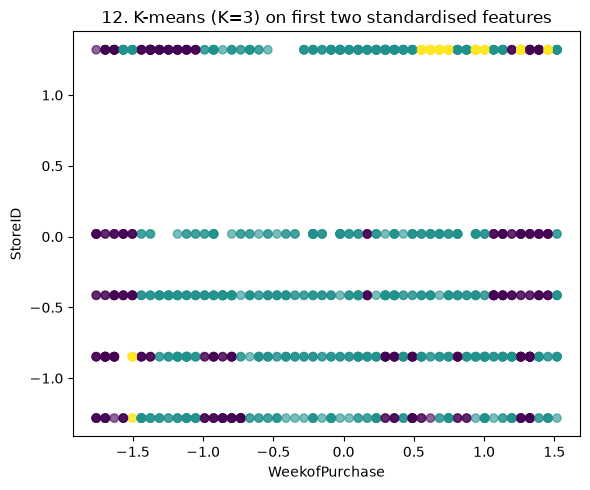

In [13]:
# 12. K-means using elbow recommendation (largest 2nd difference = sharpest bend)
second_diff = np.diff(wcss, 2)
best_k = int(np.argmax(second_diff)) + 2
print(f"12. Elbow-recommended K = {best_k}")
km = KMeans(n_clusters=best_k, n_init=25, random_state=42).fit(X)
print("    Cluster sizes:", np.bincount(km.labels_))
plt.figure(figsize=(6, 5))
plt.scatter(X[:, 0], X[:, 1], c=km.labels_, cmap="viridis", alpha=0.6)
plt.title(f"12. K-means (K={best_k}) on first two standardised features")
plt.xlabel(num.columns[0]); plt.ylabel(num.columns[1])
plt.tight_layout(); plt.show()

In [14]:
#   HIERARCHICAL CLUSTERING  
# 1-3. (data already loaded; missing values checked above)
# 4-5. Numerical attributes, standardised -> X
# 6-7. Euclidean distance + Ward linkage (Ward uses Euclidean distances on raw data)
Z = linkage(X, method="ward", metric="euclidean")

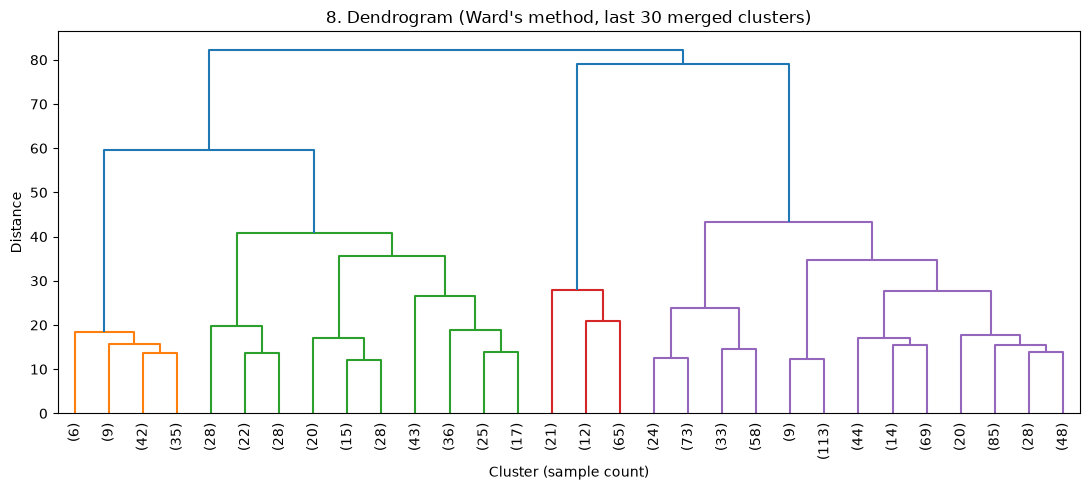

In [15]:
# 8. Dendrogram
plt.figure(figsize=(11, 5))
dendrogram(Z, truncate_mode="lastp", p=30, show_leaf_counts=True, leaf_rotation=90)
plt.title("8. Dendrogram (Ward's method, last 30 merged clusters)")
plt.xlabel("Cluster (sample count)"); plt.ylabel("Distance")
plt.tight_layout(); plt.show()

In [16]:
# 9. Cut into 3 clusters
clusters = fcluster(Z, t=3, criterion="maxclust")
print("\n9. Cluster assignments (first 20):", clusters[:20])


9. Cluster assignments (first 20): [3 1 3 1 1 3 1 1 1 1 3 2 1 3 3 3 1 3 3 3]


In [17]:
# 10. Samples per cluster
print("10. Samples in each cluster:\n", pd.Series(clusters).value_counts().sort_index())

10. Samples in each cluster:
 1    354
2     98
3    618
Name: count, dtype: int64
